# 03 · Modelagem com Machine Learning
[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jessicapmartins/previsao-faltas-consultas/blob/main/notebooks/03_modelagem_ml.ipynb)

**Pergunta:** quais consultas têm mais risco de falta, para a equipe priorizar lembretes e confirmações?

**Decisões:**
- **Separação no tempo:** treino com as consultas até 25/05/2016; teste com as consultas de 30/05 a 08/06, como se fossem a agenda da semana seguinte. Separar ao acaso deixaria o modelo "ver" dias do futuro.
- **Métricas:** ROC-AUC, PR-AUC e recall entre as consultas de maior risco. A acurácia engana: ~80% comparecem, então "ninguém falta" já acerta 80%.
- **Probabilidade bem calibrada:** o notebook 05 usa o risco previsto como probabilidade numa conta de custo. Por isso os modelos são treinados **sem** pesos de classe, e conferimos a calibração.

In [1]:
# Funções de apoio do projeto (mesma carga, mesmas variáveis e mesmo modelo em todos os notebooks)
import os, sys, urllib.request
try:
    import google.colab
    urllib.request.urlretrieve('https://raw.githubusercontent.com/jessicapmartins/previsao-faltas-consultas/main/src/apoio.py', '/content/apoio.py')
    sys.path.insert(0, '/content')
except ModuleNotFoundError:
    sys.path.insert(0, '../src')
import apoio, pandas as pd, numpy as np

con, DADOS, CSV = apoio.conectar()

def q(sql):
    """Roda uma consulta SQL no banco de consultas e devolve um DataFrame."""
    return pd.read_sql(sql, con)

apoio.garantir(con, CSV, 'base_modelo')
import matplotlib.pyplot as plt, seaborn as sns, inspect
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
sns.set_theme(style='whitegrid')

## 1. Base de modelagem e separação no tempo

In [2]:
base = q('SELECT * FROM base_modelo')
treino, teste = apoio.separar(base)
print(f'Treino: {len(treino):,} consultas · {treino.data_consulta.min()} a {treino.data_consulta.max()} · falta {treino.faltou.mean():.1%}')
print(f'Teste:  {len(teste):,} consultas · {teste.data_consulta.min()} a {teste.data_consulta.max()} · falta {teste.faltou.mean():.1%}')

Treino: 75,274 consultas · 2016-04-29 a 2016-05-25 · falta 21.0%
Teste:  35,240 consultas · 2016-05-30 a 2016-06-08 · falta 18.5%


## 2. Variáveis
A taxa de falta do bairro é calculada **só no treino** e suavizada para bairros pequenos (mistura com a taxa geral). O sexo vira `feminino` (0/1) e a deficiência vira 0/1.

In [3]:
print(inspect.getsource(apoio.taxas_bairro)); print(inspect.getsource(apoio.preparar_X))
taxa_bairro, taxa_geral = apoio.taxas_bairro(treino)
X_tr, y_tr = apoio.preparar_X(treino, taxa_bairro, taxa_geral), treino['faltou']
X_te, y_te = apoio.preparar_X(teste, taxa_bairro, taxa_geral),  teste['faltou']
X_tr.head()

def taxas_bairro(treino, minimo=50):
    """Taxa de falta por bairro no treino, suavizada para bairros com poucas consultas."""
    geral = treino['faltou'].mean()
    g = treino.groupby('bairro')['faltou'].agg(['sum', 'count'])
    return ((g['sum'] + minimo * geral) / (g['count'] + minimo)).to_dict(), geral

def preparar_X(df, taxa_bairro, taxa_geral):
    """Monta a matriz de variáveis. A taxa de falta do bairro vem SÓ do treino (evita vazamento)."""
    X = df.copy()
    X['taxa_falta_bairro'] = X['bairro'].map(taxa_bairro).fillna(taxa_geral)
    X['feminino'] = (X['genero'] == 'F').astype(int)
    X['deficiencia'] = (X['deficiencia'] > 0).astype(int)
    return X[NUMERICAS].astype(float)



,idade,antecedencia_dias,consultas_anteriores,faltas_anteriores,consultas_no_dia,taxa_falta_bairro,sms_recebido,bolsa_familia,hipertensao,diabetes,alcoolismo,deficiencia,feminino,dia_semana
2,33.0,0.0,0.0,0.0,1.0,0.209185,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0
3,12.0,3.0,0.0,0.0,1.0,0.178241,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,14.0,7.0,0.0,0.0,1.0,0.178241,1.0,0.0,0.0,0.0,0.0,0.0,1.0,5.0
5,13.0,3.0,0.0,0.0,1.0,0.236024,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0
6,16.0,0.0,0.0,0.0,1.0,0.178272,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0


## 3. Três modelos
- **Regressão logística** (com padronização): o modelo base, fácil de explicar.
- **Random Forest**: muitas árvores, cada uma vendo uma amostra.
- **Gradient Boosting** (`HistGradientBoostingClassifier` do scikit-learn): árvores em sequência, cada uma corrigindo os erros da anterior. É a mesma família do XGBoost e do LightGBM.

In [4]:
modelos = {
    'Regressão logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest':       RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=42),
    'Gradient Boosting':   apoio.modelo_final(),
}

def recall_no_topo(y, p, frac=0.2):
    """Das faltas reais, quantas estão entre as consultas com os 20% maiores riscos."""
    topo = np.argsort(-p)[:int(frac * len(p))]
    return y.values[topo].sum() / y.sum()

resultados, probs = [], {}
for nome, m in modelos.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    probs[nome] = p
    resultados.append({'modelo': nome,
                       'ROC-AUC': roc_auc_score(y_te, p),
                       'PR-AUC': average_precision_score(y_te, p),
                       'Brier': brier_score_loss(y_te, p),
                       'recall nos 20% de maior risco': recall_no_topo(y_te, p)})
resultados = pd.DataFrame(resultados).set_index('modelo')
print(f'Referência: PR-AUC de um modelo sem informação = taxa de falta do teste = {y_te.mean():.3f}')
resultados.round(3)

Referência: PR-AUC de um modelo sem informação = taxa de falta do teste = 0.185


,ROC-AUC,PR-AUC,Brier,recall nos 20% de maior risco
modelo,,,,
Regressão logística,0.679,0.309,0.146,0.355
Random Forest,0.735,0.338,0.137,0.380
Gradient Boosting,0.734,0.342,0.138,0.377


**O que aprendi:** Gradient Boosting e Random Forest empatam (ROC-AUC 0,734 e 0,735; PR-AUC 0,342 e 0,338), e a regressão logística fica atrás (0,679 e 0,309). Todos superam bem um modelo sem informação (PR-AUC 0,185). Na prática, ligando para os **20% de maior risco**, a equipe encontra **37,7% das faltas**, quase o dobro do acaso (20%). Escolhemos o **Gradient Boosting**: mesma qualidade do Random Forest e treino mais rápido nesta base.

## 4. Curvas e calibração do modelo escolhido

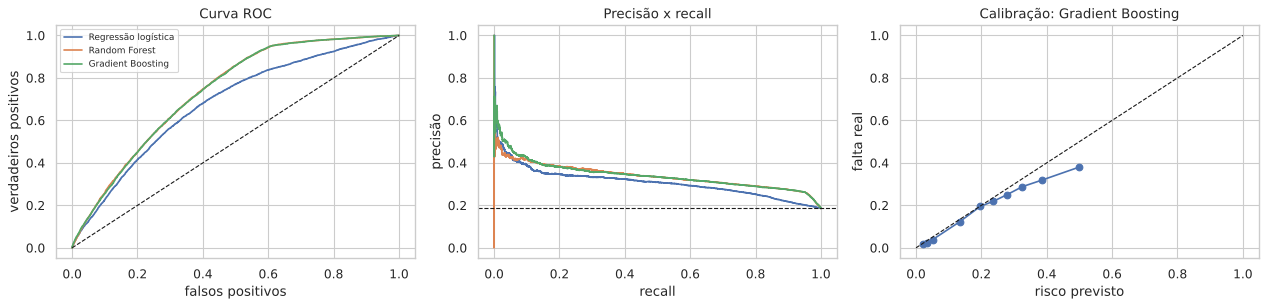

,risco_medio,falta_real,consultas
decil de risco (0 = menor),,,
0,0.020,0.017,3524
1,0.034,0.024,3524
2,0.051,0.038,3524
3,0.134,0.123,3525
4,0.197,0.195,3523
5,0.237,0.219,3524
6,0.279,0.251,3524
7,0.325,0.288,3524
8,0.386,0.320,3524


In [5]:
ESCOLHIDO = 'Gradient Boosting'
p = probs[ESCOLHIDO]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for nome, pp in probs.items():
    fpr, tpr, _ = roc_curve(y_te, pp); ax[0].plot(fpr, tpr, label=nome)
    pr, rc, _ = precision_recall_curve(y_te, pp); ax[1].plot(rc, pr, label=nome)
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_title('Curva ROC'); ax[0].set_xlabel('falsos positivos'); ax[0].set_ylabel('verdadeiros positivos')
ax[1].axhline(y_te.mean(), color='k', ls='--', lw=1); ax[1].set_title('Precisão x recall'); ax[1].set_xlabel('recall'); ax[1].set_ylabel('precisão')
ax[0].legend(fontsize=8)
frac_pos, media_prev = calibration_curve(y_te, p, n_bins=10, strategy='quantile')
ax[2].plot(media_prev, frac_pos, marker='o'); ax[2].plot([0, 1], [0, 1], 'k--', lw=1)
ax[2].set_title(f'Calibração: {ESCOLHIDO}'); ax[2].set_xlabel('risco previsto'); ax[2].set_ylabel('falta real')
plt.tight_layout(); plt.show()

decis = pd.qcut(p, 10, labels=False, duplicates='drop')
tabela = pd.DataFrame({'risco': p, 'faltou': y_te.values}).groupby(decis).agg(
    risco_medio=('risco', 'mean'), falta_real=('faltou', 'mean'), consultas=('faltou', 'size'))
tabela.index.name = 'decil de risco (0 = menor)'
tabela.round(3)

**O que aprendi:** o modelo **ordena bem** o risco: no decil de menor risco, 1,7% faltaram; no de maior risco, 38,1%. Mas **superestima no topo**: o decil de maior risco tem 50% de risco previsto e 38,1% de falta real, e o risco médio previsto (21,6%) passa da falta real (18,5%). Parte disso vem da semana de teste ter menos faltas que o treino. Em uso real, o modelo precisaria ser recalibrado com dados recentes de tempos em tempos.

## 5. O que mais pesa no risco de falta?
**Importância por permutação:** embaralha uma variável por vez no teste e mede quanto a PR-AUC cai. Quanto maior a queda, mais o modelo depende dela.

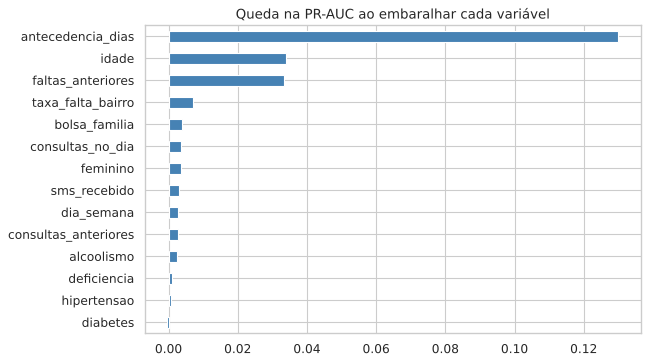

antecedencia_dias       0.1300
idade                   0.0339
faltas_anteriores       0.0335
taxa_falta_bairro       0.0069
bolsa_familia           0.0040
consultas_no_dia        0.0037
feminino                0.0035
sms_recebido            0.0029
dia_semana              0.0028
consultas_anteriores    0.0026
alcoolismo              0.0024
deficiencia             0.0009
hipertensao             0.0008
diabetes               -0.0003
dtype: float64

In [6]:
imp = permutation_importance(modelos[ESCOLHIDO], X_te, y_te, scoring='average_precision',
                             n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_te.columns).sort_values()
ax = imp.plot(kind='barh', figsize=(8, 5), color='steelblue')
ax.set_title('Queda na PR-AUC ao embaralhar cada variável'); plt.show()
imp.sort_values(ascending=False).round(4)

**O que aprendi:** a **antecedência** domina: embaralhá-la derruba a PR-AUC em 0,130. Depois vêm **idade** (0,034) e **faltas anteriores** (0,034). O bairro ajuda pouco (0,007), e SMS e condições de saúde quase nada. É o mesmo retrato do SQL e da EDA.

## 6. Salvar as previsões do teste
A tabela `previsoes` (uma linha por consulta da "agenda futura", com o risco) alimenta os notebooks 04, 05 e 06.

In [7]:
teste['risco'] = p
teste[['consulta_id', 'data_consulta', 'risco', 'faltou']].to_sql('previsoes', con, if_exists='replace', index=False)
resultados.reset_index().to_sql('resultados_modelos', con, if_exists='replace', index=False)
q('SELECT COUNT(*) AS consultas, ROUND(AVG(risco), 3) AS risco_medio, ROUND(AVG(faltou), 3) AS falta_real FROM previsoes')

,consultas,risco_medio,falta_real
0,35240,0.216,0.185


## Conclusão
O modelo serve para **priorizar**, não para prever com certeza: com PR-AUC de 0,34, ele concentra quase o dobro de faltas no topo da lista do que uma escolha ao acaso. Limitações: a base cobre só 6 semanas, a maioria dos pacientes não tem histórico, e faltam variáveis importantes, como especialidade, horário da consulta, distância e clima. Próximos passos: recalibrar o risco com dados recentes, incluir essas variáveis e monitorar a taxa de falta por faixa de risco depois de colocar em uso.

## Gravar no Google Drive
Fecha o banco e força o Drive a gravar agora. Sem isso, o próximo notebook pode não enxergar as tabelas novas.

In [8]:
con.commit()
con.close()
try:
    from google.colab import drive
    drive.flush_and_unmount()
    print('Banco gravado no Google Drive.')
except ModuleNotFoundError:
    print('Fora do Colab: nada a sincronizar.')

Fora do Colab: nada a sincronizar.
